# Sesión 04 — Regularización (Ridge, Lasso) y validación cruzada

**Bloque:** 2 · Regresión

## Objetivos

Al terminar esta sesión deberías ser capaz de:

- Demostrar con números por qué una sola partición train/test puede engañarte, y medir esa inestabilidad con validación cruzada.
- Elegir el número de *folds* de una validación cruzada y justificar la elección, en lugar de poner 5 por costumbre.
- Aplicar `Ridge` y `Lasso` a un problema de regresión y explicar qué le hace cada uno a los coeficientes.
- Ajustar el hiperparámetro `alpha` con `RidgeCV` y `LassoCV` en vez de a ojo, sabiendo qué se está optimizando por dentro.
- Elegir entre Ridge y Lasso a partir de lo que pide el encargo — precisión máxima o una lista corta de variables — y defender la decisión ante alguien que defienda la otra.
- Reconocer cuándo la regularización no te va a servir de nada, mirando la relación entre el número de filas y el de columnas.

## Qué necesitas de antes

- **S03 — Regresión lineal simple y múltiple**: `train_test_split`, `LinearRegression`, lectura de R², MAE y RMSE, e interpretación de coeficientes.
- La idea de que un modelo se evalúa siempre sobre datos que no ha visto.
- Del ejercicio 3 de S03 quedó una pregunta abierta: *"prueba a estandarizar las variables y compara los coeficientes"*. Hoy el escalado deja de ser opcional.

## 1. El problema: la suerte en el muestreo

En la sesión anterior partimos los datos en entrenamiento y prueba, entrenamos y medimos. Parecía riguroso. Pero esa medición depende de **una sola tirada de dados**: la de `train_test_split`. ¿Y si en el conjunto de prueba cayeron por casualidad los casos más fáciles? El error saldría artificialmente bajo. ¿Y si cayeron los más raros? Al revés.

La **validación cruzada** (*cross-validation*) sustituye esa única tirada por varias. En su versión más común, **K-Fold**:

1. Se parte el conjunto de entrenamiento en K bloques o *folds* (por ejemplo, 5).
2. Se entrena el modelo K veces. En cada una, K−1 bloques sirven para entrenar y el restante para medir.
3. Cada bloque hace de conjunto de validación exactamente una vez.
4. Se promedian las K mediciones.

Lo importante no es solo la media: es **la dispersión**. Si los K resultados se parecen entre sí, la estimación es fiable. Si bailan mucho, el modelo depende demasiado de qué filas le tocaron, y cualquier número que reportes será medio invento.

**Qué problema resuelve:** dar una estimación del error más estable que la de una sola partición, y de paso decirte cuánto te puedes fiar de ella.

**Cuándo elegirla:** casi siempre, y de forma obligada cuando el dataset es pequeño (unos pocos miles de filas o menos) o cuando vas a comparar varios modelos entre sí. Comparar dos modelos sobre una única partición es comparar dos tiradas de dados.

**Cuándo NO:** cuando entrenar es tan caro que multiplicar por K es inviable, y cuando los datos tienen orden temporal — ahí barajar las filas es hacer trampa, porque entrenarías con el futuro para predecir el pasado. Eso se ve en S22.

**Qué asume:** que las filas son independientes entre sí y que todas vienen de la misma población. Si hay grupos (varias filas del mismo cliente, del mismo hospital), un K-Fold normal reparte el mismo grupo entre entrenamiento y validación y te devuelve un resultado demasiado optimista.

> **Ojo con el vocabulario.** La validación cruzada se hace **dentro** del conjunto de entrenamiento. El conjunto de test sigue guardado y sin tocar hasta el final. Son dos cosas distintas y se mezclan constantemente.

In [1]:
# Librerías de siempre
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Herramientas de scikit-learn
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error

sns.set_theme(style="whitegrid")

### El caso: precio de vivienda en Ames, Iowa

Trabajamos con el dataset **Ames Housing**: 1.460 viviendas vendidas entre 2006 y 2010, descritas con 80 columnas. Nuestro objetivo es predecir `SalePrice`.

Es un dataset deliberadamente incómodo, y por eso sirve. Tiene muchas variables, y varias miden **casi lo mismo**: `GrLivArea` (superficie habitable) frente a `1stFlrSF` + `2ndFlrSF` (superficie por planta); `GarageCars` (plazas de garaje) frente a `GarageArea` (metros de garaje); `TotRmsAbvGrd` (número de habitaciones) frente a la superficie. Un modelo lineal con variables redundantes reparte la influencia entre ellas de forma arbitraria e inestable.

Lo cargamos desde OpenML, así que la primera ejecución tarda unos segundos mientras se descarga.

In [2]:
# Descarga desde OpenML (la primera vez tarda unos segundos; después queda cacheado)
ames = fetch_openml(data_id=42165, as_frame=True, parser="auto")
df = ames.frame

print(f"Dimensiones: {df.shape[0]} viviendas x {df.shape[1]} columnas")
print("\nAlgunas columnas representativas:")
print(df[['OverallQual', 'GrLivArea', 'YearBuilt', 'GarageCars', 'SalePrice']].head())

Dimensiones: 1460 viviendas x 81 columnas

Algunas columnas representativas:
   OverallQual  GrLivArea  YearBuilt  GarageCars  SalePrice
0            7       1710       2003           2     208500
1            6       1262       1976           2     181500
2            7       1786       2001           2     223500
3            7       1717       1915           3     140000
4            8       2198       2000           3     250000


In [3]:
# ¿Cuántas columnas son numéricas y cuántas son texto?
print(df.dtypes.value_counts())
print(f"\nColumnas con algún valor nulo: {(df.isnull().sum() > 0).sum()}")

str        43
int64      35
float64     3
Name: count, dtype: int64

Columnas con algún valor nulo: 19


### Exploración inicial (EDA)

Antes de modelar, miramos los datos. Tres preguntas:

1. ¿Cómo se distribuye `SalePrice`?
2. ¿Se nota la calidad general de la vivienda (`OverallQual`, de 1 a 10) en el precio?
3. ¿Y la superficie habitable (`GrLivArea`)?

1. La mayoria estan entre los 100.000 y los 200.000 pero hay algunas que suben hasta los 755.000, Porque el error $RMSE$ penaliza mucho los errores grandes al elevarlos al cuadrado. Las predicciones en esas pocas casas carísimas van a dominar el error de todo el modelo.

2. Vemos claramente que cuanto mas precio mas calidad de la casa, aun que hay valores que vemos en forma de puntititos que no estan en la media seguyn precio calidad

3. tambien sigue una subida lineal, cuantos mas metros mas cara es la casa, aun que hay casa grandes vendidas baratas, aqui tenemos mas distorsion que overallqual

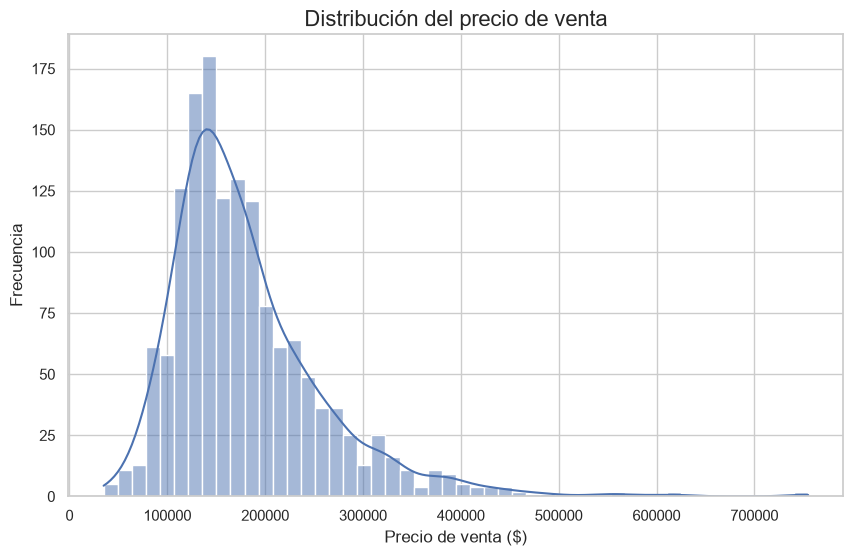

Mediana: $163,000   Máximo: $755,000   Asimetría: 1.88


In [4]:
# 1. Distribución del precio de venta
plt.figure(figsize=(10, 6))
sns.histplot(df['SalePrice'], kde=True, bins=50)
plt.title('Distribución del precio de venta', fontsize=16)
plt.xlabel('Precio de venta ($)')
plt.ylabel('Frecuencia')
plt.show()

print(f"Mediana: ${df['SalePrice'].median():,.0f}   "
      f"Máximo: ${df['SalePrice'].max():,.0f}   "
      f"Asimetría: {df['SalePrice'].skew():.2f}")

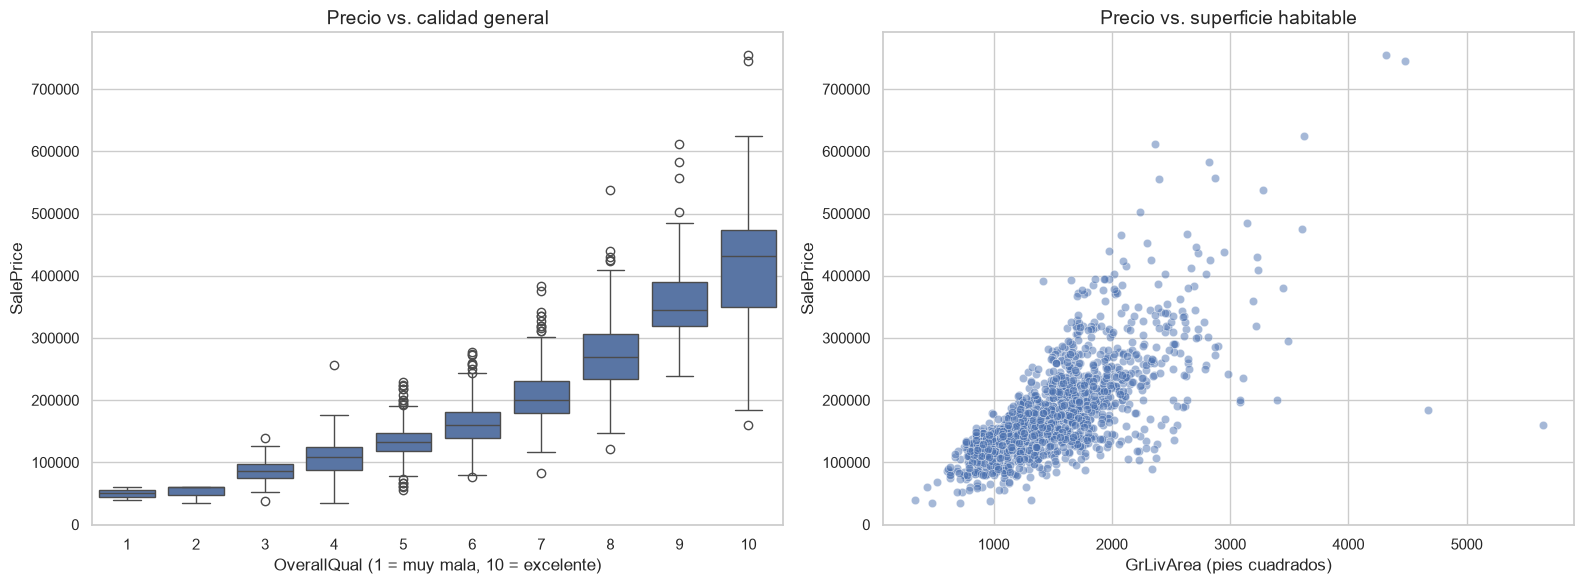

Correlación de OverallQual con el precio: 0.791
Correlación de GrLivArea con el precio:   0.709


In [5]:
# 2 y 3. Dos variables candidatas frente al precio
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(x='OverallQual', y='SalePrice', data=df, ax=ax[0])
ax[0].set_title('Precio vs. calidad general', fontsize=14)
ax[0].set_xlabel('OverallQual (1 = muy mala, 10 = excelente)')

sns.scatterplot(x='GrLivArea', y='SalePrice', data=df, ax=ax[1], alpha=0.5)
ax[1].set_title('Precio vs. superficie habitable', fontsize=14)
ax[1].set_xlabel('GrLivArea (pies cuadrados)')

plt.tight_layout()
plt.show()

print(f"Correlación de OverallQual con el precio: {df['OverallQual'].corr(df['SalePrice']):.3f}")
print(f"Correlación de GrLivArea con el precio:   {df['GrLivArea'].corr(df['SalePrice']):.3f}")

**Qué se ve.**

La distribución del precio está **sesgada a la derecha**: muchas casas en la franja de 100.000–200.000 $ y una cola larga de casas caras. La mediana ronda los 163.000 $ y el máximo se va a 755.000 $. Es lo normal en vivienda, y tiene una consecuencia práctica: el RMSE, que penaliza los errores grandes al cuadrado, va a estar dominado por lo que hagamos con esas pocas casas caras.

`OverallQual` sube el precio de forma clara y bastante monótona, y es la variable mejor correlacionada del dataset. `GrLivArea` también sube, pero con más dispersión y con algún caso llamativo: casas enormes vendidas baratas, abajo a la derecha del gráfico.

Nada de esto nos dice todavía **qué variables sobran**, que es el problema de hoy. Para eso hacen falta las 36 numéricas a la vez, no dos.

## Preparación de los datos

Cinco pasos antes de modelar:

1. **Quedarnos con las columnas numéricas.** Las de texto (`Neighborhood`, `ExterQual`...) necesitarían codificación; las dejamos fuera hoy para no mezclar dos problemas.
2. **Rellenar los nulos** con la mediana de cada columna. `StandardScaler` no admite huecos, y la mediana aguanta bien los valores extremos.
3. **Separar `X` e `y`.**
4. **Escalar con `StandardScaler`.** Esto hoy **no es opcional**. La regularización penaliza el tamaño de los coeficientes, y el tamaño de un coeficiente depende de las unidades de su variable: un coeficiente por pie cuadrado es pequeño y uno por número de baños es grande, aunque midan efectos parecidos. Sin escalar, la penalización castigaría a unas variables mucho más que a otras solo por cómo están medidas.
5. **Inyectar ruido.** Añadimos cinco columnas de números aleatorios, sin ninguna relación con el precio. Son un control: sabemos con certeza que no sirven para nada, así que nos dicen si el modelo es capaz de darse cuenta.

In [6]:
# 1. Solo columnas numéricas (y fuera el identificador, que no es una variable)
df_numeric = df.select_dtypes(include=np.number).copy()
df_numeric = df_numeric.drop(columns=['Id'], errors='ignore')

print(f"Nos quedamos con {df_numeric.shape[1]} columnas numéricas (SalePrice incluida)")
print("\nColumnas con nulos antes de imputar:")
print(df_numeric.isnull().sum()[lambda s: s > 0])

# 2. Nulos -> mediana de la columna
for col in df_numeric.columns:
    if df_numeric[col].isnull().any():
        df_numeric[col] = df_numeric[col].fillna(df_numeric[col].median())

print(f"\nNulos restantes: {df_numeric.isnull().sum().sum()}")

Nos quedamos con 37 columnas numéricas (SalePrice incluida)

Columnas con nulos antes de imputar:
LotFrontage    259
MasVnrArea       8
GarageYrBlt     81
dtype: int64

Nulos restantes: 0


In [7]:
# 3. Separar X e y
X = df_numeric.drop('SalePrice', axis=1)
y = df_numeric['SalePrice']

# 4. Escalado: media 0 y desviación 1 en todas las columnas
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Inyección de ruido: 5 columnas aleatorias sin relación con el precio
#    La semilla fija hace que el "ruido" sea siempre el mismo y el experimento reproducible
np.random.seed(42)
ruido = np.random.rand(X_scaled.shape[0], 5)
X_scaled_ruido = np.hstack((X_scaled, ruido))

# Guardamos los nombres para poder leer los coeficientes más adelante
columnas = list(X.columns) + [f'ruido_{i + 1}' for i in range(5)]

print(f"X original:        {X_scaled.shape}")
print(f"X con ruido:       {X_scaled_ruido.shape}")
print(f"Últimas columnas:  {columnas[-7:]}")

X original:        (1460, 36)
X con ruido:       (1460, 41)
Últimas columnas:  ['MoSold', 'YrSold', 'ruido_1', 'ruido_2', 'ruido_3', 'ruido_4', 'ruido_5']


In [8]:
# 6. División en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled_ruido, y, test_size=0.2, random_state=42
)

print(f"Entrenamiento: {X_train.shape[0]} viviendas")
print(f"Prueba:        {X_test.shape[0]} viviendas")
print(f"\nRelación filas/columnas en entrenamiento: {X_train.shape[0] / X_train.shape[1]:.0f} a 1")

Entrenamiento: 1168 viviendas
Prueba:        292 viviendas

Relación filas/columnas en entrenamiento: 28 a 1


### *Baseline*: regresión lineal, pero medida con validación cruzada

El modelo de la sesión anterior, sin ningún cambio. Lo único distinto es **cómo lo medimos**: en vez de una partición, cinco.

`cross_val_score` devuelve un valor por *fold*. Como scikit-learn siempre maximiza, las métricas de error se le pasan en negativo (`neg_mean_squared_error`); por eso hay que cambiarle el signo antes de la raíz.

In [9]:
lr = LinearRegression()

# 5 folds dentro del conjunto de entrenamiento. El test no se toca.
scores_lr = cross_val_score(lr, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
rmse_lr = np.sqrt(-scores_lr)

print("----- LinearRegression -----")
print("RMSE de cada fold:")
for i, r in enumerate(rmse_lr, 1):
    print(f"  fold {i}: ${r:,.0f}")
print(f"\nRMSE promedio (CV):    ${rmse_lr.mean():,.0f}")
print(f"Desviación típica (CV): ${rmse_lr.std():,.0f}")

# Y ahora sí, el conjunto de test, una sola vez
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
rmse_lr_test = np.sqrt(mean_squared_error(y_test, y_pred_lr))
print(f"\nRMSE en test:          ${rmse_lr_test:,.0f}")

----- LinearRegression -----
RMSE de cada fold:
  fold 1: $39,968
  fold 2: $38,719
  fold 3: $54,794
  fold 4: $26,099
  fold 5: $27,228

RMSE promedio (CV):    $37,362
Desviación típica (CV): $10,412

RMSE en test:          $36,835


**Esto es lo importante de toda la primera parte de la sesión.**

Mira los cinco *folds*. No se parecen: hay uno por debajo de 27.000 $ y otro por encima de 54.000 $. La desviación típica es de unos 10.000 $ sobre una media de 37.000 — más de una cuarta parte.

Si hubiéramos hecho una sola partición y nos hubiera tocado el *fold* bueno, habríamos ido a contarle al cliente que el modelo se equivoca unos 26.000 $. Y le habríamos mentido, sin saberlo.

Ese baile tiene dos causas posibles, y conviene no confundirlas: puede que el dataset sea pequeño y heterogéneo (1.168 filas de entrenamiento, con casas muy caras repartidas de forma desigual), o puede que el modelo sea **inestable** porque tiene 41 variables, varias redundantes, y reparte su influencia de forma distinta según qué filas vea. La segunda causa sí tiene arreglo, y es lo que viene ahora.

---
### Preguntas de recap — Validación cruzada

1. ¿En qué se diferencia un *fold* de validación cruzada del conjunto de test?
2. ¿Por qué `cross_val_score` devuelve el error en negativo?
3. Si subes de `cv=5` a `cv=20`, ¿qué ganas y qué pagas?
4. Tu validación cruzada da una media excelente y una desviación típica enorme. ¿Reportarías solo la media?
5. Tienes un dataset con varias visitas del mismo paciente. ¿Qué le pasa a un K-Fold normal aquí?

---

1- El fold se hace dentro del conjunto de entrenamiento, en cambio el conjunto de test es el examen final, ese no se usa para entrenar, solo se abre una vez al final del proyecto, es como un examen, te lo miras nuna vez y ya 

2- scikit-learn, aplica cuanto mayor es el num mejor, y bsucamos lo contrano que sean lo mas pequeño posibles, al hacer esto le cambiamos el signo, por eso despues al final de todo para aplicar la raiz cuadrada le cambiamos el sino 

3- Entrenas el modelo con una mayor porcion de datos, con 5, haces 20% 4 paquetes y uno de 20& para el examen, con cv=20 son 20 paquetes es decir 5% cada uno, el modelo estudia mas y mas se parece la prueba al modelo final, lo malo es que tardas el doble ya que son muchos mas test y que perdemos datos a la hora de examinar

4- Reportar solo la media serai engañoso, esta diesviacion indica que el modelo es inestable, y es esuerte, depende del trozo de datos que le toque en cada prueba, se reportan los dos para reflejar el margen real de incertidumbre

5- Esto a uno normal lo que pasa es que se memorza el mismo paciente, unos del apciente a para estudiar, y unas del paciente a para examen, cuando le pongas el paciente b de examen la lia, para solucionar esto se usa group k fold, para agrupar por id de paciente 

Queremos predecir la evolucion de bitcoin y tenemos datos de 2020

A la hora de testear con temporalidd 
A la hroa de testear seria de enero a octubre 
Para testear seria de octube a diciembre 

## 2. La solución: regularización

Un modelo lineal con muchas variables tiende a **sobreajustar**: se pega tanto a los datos de entrenamiento que acaba memorizando el ruido en vez de aprender la señal. Se nota porque va muy bien en entrenamiento y peor en datos nuevos.

La **regularización** ataca esto cambiando lo que el modelo intenta minimizar. En vez de pedirle solo "equivócate lo menos posible", le pedimos dos cosas a la vez: *"equivócate poco **y además** mantén los coeficientes pequeños"*. Un coeficiente grande significa que el modelo apuesta fuerte por una variable; obligarle a apostar con moderación es lo que le impide inventarse relaciones que no existen.

Hay dos formas clásicas de medir "coeficientes pequeños", y la diferencia entre ambas no es un detalle técnico:

- **Ridge (L2)** penaliza la **suma de los cuadrados** de los coeficientes. Los encoge a todos hacia cero, pero **nunca llegan a cero exactamente**. Cuando dos variables miden casi lo mismo, Ridge reparte la influencia entre las dos en vez de escoger.
- **Lasso (L1)** penaliza la **suma de los valores absolutos**. Esta forma de penalizar sí lleva coeficientes a **cero exacto**, lo que equivale a **eliminar variables del modelo**. Cuando dos variables miden casi lo mismo, Lasso tiende a quedarse con una y tirar la otra.

El parámetro **`alpha`** controla la fuerza de la penalización. Con `alpha` = 0 vuelves a la regresión lineal de siempre. Cuanto más alto, más simple el modelo — y si te pasas, tan simple que ya no predice nada. No hay un valor bueno *a priori*: se busca, y se busca con validación cruzada. De ahí que `RidgeCV` y `LassoCV` existan.

**Qué problema resuelve:** modelos inestables por tener demasiadas variables o variables redundantes entre sí.

**Cuándo elegirla:** cuando tienes muchas columnas en relación al número de filas, cuando sospechas que hay variables que miden lo mismo, o cuando necesitas una lista corta de factores que explicar a alguien (ahí, Lasso).

**Cuándo NO:** cuando tienes muchísimas más filas que columnas y todas las variables aportan — la penalización solo te quitará precisión a cambio de nada. Lo comprobarás tú mismo en el ejercicio 3.

**Qué asume:** que las variables están **en la misma escala**. Sin escalar, la penalización castiga a cada variable según sus unidades y el resultado no significa nada. Asume además todo lo que ya asumía la regresión lineal: relación lineal y errores bien portados.

### Demostración: `LassoCV`

`LassoCV` hace dos cosas de una vez: prueba una lista de valores de `alpha` y, para cada uno, lo evalúa con validación cruzada. Se queda con el mejor y reentrena con él.

La lista de `alpha` la damos en escala logarítmica, porque lo que importa es el orden de magnitud, no la diferencia: entre 0,001 y 0,01 hay tanta distancia conceptual como entre 100 y 1.000.

In [10]:
# Probamos 13 valores de alpha repartidos entre 0,000001 y 1.000.000
lasso_cv = LassoCV(alphas=np.logspace(-6, 6, 13), cv=5, random_state=42)
lasso_cv.fit(X_train, y_train)

print("----- LassoCV -----")
print(f"Mejor alpha encontrado: {lasso_cv.alpha_:,.6f}")

# LassoCV guarda el MSE de cada alpha en cada fold dentro de mse_path_
rmse_lasso_cv = np.sqrt(lasso_cv.mse_path_.mean(axis=1)).min()
print(f"RMSE promedio (CV):     ${rmse_lasso_cv:,.0f}")

y_pred_lasso = lasso_cv.predict(X_test)
rmse_lasso_test = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
print(f"RMSE en test:           ${rmse_lasso_test:,.0f}")

print("\n===== COMPARACIÓN =====")
print(f"LinearRegression -> RMSE test: ${rmse_lr_test:,.0f}")
print(f"LassoCV          -> RMSE test: ${rmse_lasso_test:,.0f}")

----- LassoCV -----
Mejor alpha encontrado: 1,000.000000
RMSE promedio (CV):     $38,031
RMSE en test:           $37,262

===== COMPARACIÓN =====
LinearRegression -> RMSE test: $36,835
LassoCV          -> RMSE test: $37,262


**Un resultado que no era el esperado.** Lasso **no** ha mejorado a la regresión lineal: sale unos cientos de dólares peor.

Antes de dar por fracasado el experimento, conviene mirar qué ha hecho por dentro. Ese es justo el ejercicio.

$\alpha$ es la rosca del freno de mano: Controla con cuánta fuerza castigamos al modelo para que no se vuelva loco memorizando ruido o pistas falsas.  

Si $\alpha = 0$: El freno está suelto del todo; el modelo actúa a lo loco como la regresión normal y se traga toda la basura

Si subes $\alpha$: Le cobras una "multa" por usar cada variable; Lasso aplasta sus números y manda a cero a las que no aportan nada para despedirlas

El objetivo: Probar varios niveles de $\alpha$ en la fase de estudio para dar con la multa perfecta: limpiar las columnas chatarra sin cargarte las pistas buenas.

---
## Ejercicio 1 — ¿Qué ha decidido tirar Lasso?

**Contexto.** Trabajas en una consultora inmobiliaria. El equipo de tasación te pide un modelo, pero sobre todo te pide algo que puedan usar: *"dinos qué mirar cuando entramos en una casa"*. Ahora mismo tienen 41 variables sobre la mesa y no saben cuáles importan.

Acabas de entrenar un Lasso. Su promesa es que pone a cero las variables que no aportan. Vamos a comprobar si cumple, y tienes un control perfecto para hacerlo: **las cinco columnas de ruido que inyectaste tú mismo**. Sabes con total certeza que no sirven para nada. Si Lasso no las descarta, tampoco te puedes fiar del resto de su criterio.

**Tu tarea.**
1. Extrae los coeficientes del modelo (`lasso_cv.coef_`) y móntalos en un `pd.Series` usando `columnas` como índice, para poder leerlos por nombre.
2. Cuenta cuántos coeficientes son exactamente cero.
3. Comprueba **específicamente qué ha pasado con las cinco variables de ruido**.
4. Lista qué variables **reales** ha descartado. Mira si alguna te sorprende.
5. Dibuja un gráfico de barras con los 10 coeficientes positivos más grandes: los factores que, según el modelo, más suben el precio.

**Criterio de que lo has hecho bien:** las cinco de ruido tienen que estar a cero — si no, algo falla en tu código. Y el modelo debería haber descartado bastantes variables reales además del ruido, entre ellas alguna que a primera vista parecía tener sentido.

Total de coeficientes reducidos a cero: 18
Coeficientes de las variables de ruido (deben ser 0.0):
ruido_1    0.0
ruido_2    0.0
ruido_3    0.0
ruido_4   -0.0
ruido_5   -0.0
dtype: float64
Variables reales descartadas por Lasso:
BsmtFinSF2      -0.0
BsmtUnfSF        0.0
2ndFlrSF         0.0
LowQualFinSF    -0.0
BsmtHalfBath    -0.0
HalfBath        -0.0
GarageArea       0.0
OpenPorchSF      0.0
EnclosedPorch   -0.0
PoolArea        -0.0
MiscVal         -0.0
MoSold          -0.0
YrSold          -0.0
dtype: float64


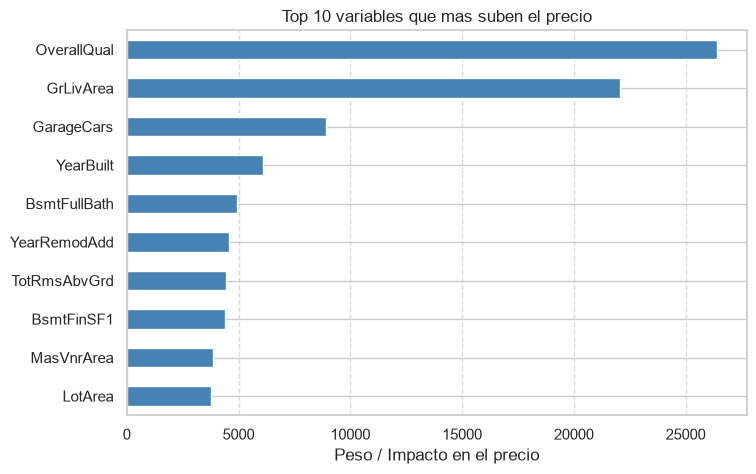

In [11]:
# TODO: completa esta celda
# Los coeficientes salen en el mismo orden que la lista `columnas` que construiste al preparar los datos.
# Para el gráfico horizontal, ordena la serie antes de dibujarla o las barras saldrán del revés.

import pandas as pd
import matplotlib.pyplot as plt

# Sacamos los pesos de Lasso y les pegamos la etiqueta con el nombre de su columna
coefs = pd.Series(
    lasso_cv.coef_, index=columnas
)  # Junta el numero de peso de Lasso con el nombre de su columna correspondiente

#-------------------------------------------------------------------------



#punto 2 contar cuantas coeficientes son 0, es decir las columnas que tienen exacatamento 0 como valor

# Contamos cuántas variables ha mandado Lasso directamente a la basura (cero)
ceros = (coefs == 0).sum()  # Cuenta cuántas variables tienen peso cero absoluto
print(f"Total de coeficientes reducidos a cero: {ceros}")



#-------------------------------------------------------------------------




#punto 3 comprobamos si las 5 columnas de ruido han sido eliminadas por Lasso
# osea el punto 3 buscamos el coeficiente de las 5 columnas que le hemos añadido para ver si estan a 0.0
# Buscamos las 5 columnas de mentira y comprobamos si Lasso las ha eliminado todas
cols_ruido = [
    c for c in columnas if "ruido" in c.lower()
]  # Filtra los nombres de las 5 columnas con números al azar
print("Coeficientes de las variables de ruido (deben ser 0.0):")
print(
    coefs[cols_ruido]
)  # Muestra el valor exacto asignado a cada una de las 5 de mentira

#-------------------------------------------------------------------------




# listar cuáles son esas 13 variables reales descartadas.
# Punto 4: Filtramos las variables eliminadas para ver solo las reales de la casa
descartadas = coefs[
    coefs == 0
]  # Se queda únicamente con las variables que tienen peso cero absoluto
reales_descartadas = descartadas[
    ~descartadas.index.isin(cols_ruido)
]  # Quita las 5 de ruido para mostrar solo las verdaderas de la casa

print("Variables reales descartadas por Lasso:")
print(
    reales_descartadas
)  # Muestra en pantalla la lista de características reales que ha tirado





#-------------------------------------------------------------------------

# una vez hemos visto las que estan eliminados, dibijamos el grafico de la variable de coef y sacmaos las 10 variables que en vez de doeficiente 0 tienen mas (son mas importantes)
# Punto 5: Filtramos los 10 pesos positivos mas grandes y los dibujamos en un grafico
top10 = coefs.sort_values(ascending=False).head(
    10
)  # Ordena las variables de mayor a menor importancia y coge las 10 primeras
# esta variable saca saca las 10 con mejor coefiecnete






plt.figure(figsize=(8, 5))  # Cambia el tamano de la ventana para que la imagen se vea grande
top10.sort_values().plot(
    kind="barh", color="steelblue"
)  # Dibuja las 10 barras tumbadas dejando la mas importante arriba del todo




plt.title(
    "Top 10 variables que mas suben el precio"
)  # Pone el texto del titulo arriba del grafico
plt.xlabel(
    "Peso / Impacto en el precio"
)  # Pone la etiqueta abajo para explicar que miden las barras
plt.grid(
    axis="x", linestyle="--", alpha=0.7
)  # Dibuja lineas verticales discontinuas de fondo para leer mejor las cifras
plt.show()  # Despliega la foto del grafico final en pantalla


—— Task 1: Coefficients Overview ——
MSSubClass      -6655.417840
LotFrontage      -626.297716
LotArea          3752.637526
OverallQual     26416.392290
OverallCond      2578.396602
YearBuilt        6113.698411
YearRemodAdd     4562.521410
MasVnrArea       3835.870666
BsmtFinSF1       4386.833365
BsmtFinSF2         -0.000000
dtype: float64
Total features evaluated: 41

—— Task 2: Zero Coefficients Count ——
Number of zeroed-out coefficients: 18 / 41

—— Task 3: Noise Features Inspection ——
ruido_1    0.0
ruido_2    0.0
ruido_3    0.0
ruido_4   -0.0
ruido_5   -0.0
dtype: float64
Did Lasso drop all injected noise columns? -> True

—— Task 4: Real Features Discarded by Lasso ——
Count of real features discarded: 13
['BsmtFinSF2', 'BsmtUnfSF', '2ndFlrSF', 'LowQualFinSF', 'BsmtHalfBath', 'HalfBath', 'GarageArea', 'OpenPorchSF', 'EnclosedPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']


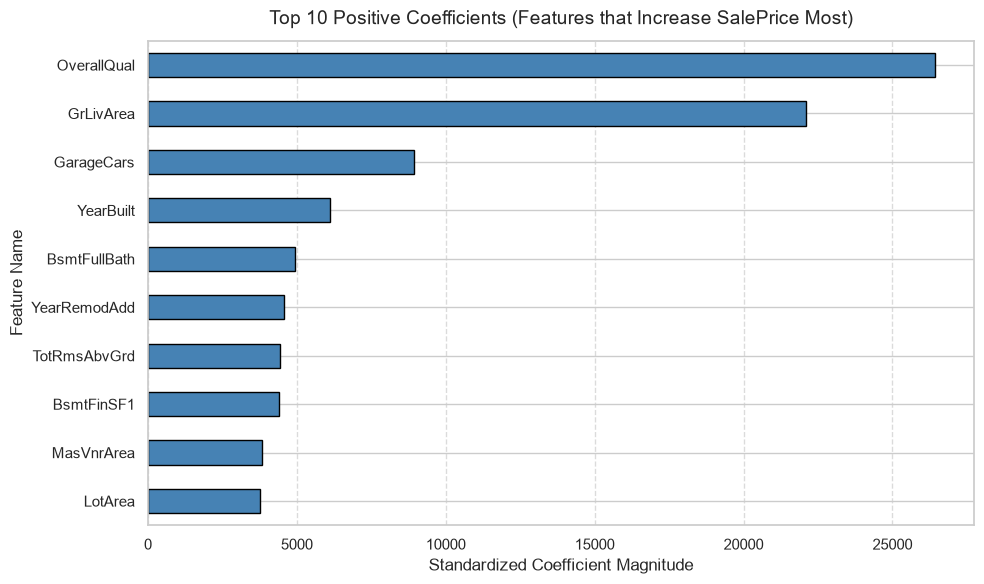

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Extrae coeficientes
lasso_coefs = pd.Series(lasso_cv.coef_, index=columnas)  # Junta el peso numérico de Lasso con el nombre de cada columna[cite: 5]
print("—— Task 1: Coefficients Overview ——")  # Imprime el encabezado de la tarea 1[cite: 5]
print(lasso_coefs.head(10))  # Enseña las 10 primeras variables con su peso[cite: 5]
print(f"Total features evaluated: {len(lasso_coefs)}")  # Cuenta cuántas columnas tenía el dataset en total[cite: 5]

# 2. Cuenta cuántos coeficientes son cero
zero_coef_count = (lasso_coefs == 0).sum()  # Cuenta cuántas variables ha mandado Lasso directamente a cero[cite: 5, 6]
print("\n—— Task 2: Zero Coefficients Count ——")  # Imprime el encabezado de la tarea 2[cite: 5, 6]
print(f"Number of zeroed-out coefficients: {zero_coef_count} / {len(lasso_coefs)}")  # Muestra las eliminadas frente al total[cite: 5, 6]

# 3. Comprueba qué ha pasado con el ruido
noise_features = [f'ruido_{i + 1}' for i in range(5)]  # Crea la lista ['ruido_1', ..., 'ruido_5'][cite: 5, 6]
noise_coefficients = lasso_coefs.loc[noise_features]  # Busca exactamente esas 5 variables de mentira en los coeficientes[cite: 5, 6]
print("\n—— Task 3: Noise Features Inspection ——")  # Imprime el encabezado de la tarea 3[cite: 5, 6]
print(noise_coefficients)  # Enseña los valores exactos asignados a las 5 de ruido[cite: 5, 6]
all_noise_zero = (noise_coefficients == 0).all()  # Pregunta si TODAS las variables de ruido valen 0.0 (True/False)[cite: 5, 6]
print(f"Did Lasso drop all injected noise columns? -> {all_noise_zero}")  # Imprime si Lasso borró el ruido con un True directo[cite: 5, 6]

# 4. Lista variables reales descartadas
dropped_all = lasso_coefs[lasso_coefs == 0]  # Guarda únicamente todas las variables con peso cero[cite: 5, 6]
dropped_real = dropped_all.drop(index=noise_features, errors='ignore')  # Elimina las 5 de ruido para dejar solo las reales[cite: 5, 6]
print("\n—— Task 4: Real Features Discarded by Lasso ——")  # Imprime el encabezado de la tarea 4[cite: 5, 6]
print(f"Count of real features discarded: {len(dropped_real)}")  # Cuenta cuántas características reales ha tirado Lasso[cite: 5, 6]
print(dropped_real.index.tolist())  # Enseña solo la lista con los nombres de las variables reales borradas[cite: 5, 6]

# 5. Dibuja gráfico Top 10 positivo
top_positive = lasso_coefs[lasso_coefs > 0].nlargest(10).sort_values(ascending=True)  # Coge las 10 mejores y reordena para el gráfico[cite: 5, 6]
plt.figure(figsize=(10, 6))  # Define el tamaño de la ventana del gráfico[cite: 5, 6]
top_positive.plot(kind='barh', color='steelblue', edgecolor='black')  # Dibuja barras tumbadas con borde negro[cite: 5, 6]
plt.title('Top 10 Positive Coefficients (Features that Increase SalePrice Most)', fontsize=14, pad=12)  # Pone el título arriba[cite: 6]
plt.xlabel('Standardized Coefficient Magnitude', fontsize=12)  # Pone el texto del eje horizontal[cite: 6]
plt.ylabel('Feature Name', fontsize=12)  # Pone el texto del eje vertical[cite: 6]
plt.grid(axis='x', linestyle='--', alpha=0.7)  # Añade rejilla punteada vertical de fondo[cite: 5, 6]
plt.tight_layout()  # Ajusta márgenes para que no se corte nada[cite: 6]
plt.show()  # Muestra el gráfico final[cite: 6]

### Mis reflexiones

*(Escribe aquí tu respuesta antes de seguir)*

- Lasso ha descartado `GarageArea` pero ha mantenido `GarageCars`. ¿Dirías que la superficie del garaje no influye en el precio de una casa? Ten cuidado con la respuesta, y explica en qué se diferencia "no influye" de "no aporta nada nuevo".
- Las cinco variables de ruido han caído. ¿Qué habrías concluido sobre el modelo si solo hubieran caído tres? ¿Habrías podido fiarte del resto de descartes?
- El modelo predice algo peor que la regresión lineal sin regularizar, pero usa la mitad de variables. Para el encargo del equipo de tasación, ¿eso es un precio que pagarías? ¿Y si el encargo fuera fijar el precio de salida en un portal inmobiliario, sin nadie mirando?

1- Si que influye el tamaño del garaje pero, este no aporta nada nuevo ya que con la variable de gragae cars ya tenemos sufiociente esntonces nos sobra la de garaje area, osea si que influye pero no nos aporta nada nuevo por que ya la tenemos en la de garage area 

2- Si el modelo se hubiera dejado engañar no nos pdoemos fiar del modelo, entonces tampoco nos podriamos fiar del resto de descartes ni de las que ha mantenido ya que sabriamos que el aplastamiento de aplha no era lo suficiente estricto como para limpiar ruido 

3- Para un equipo si, a un tasador le resulta mas facio revisar solo 15 columnas clave en una visita que medir las 41, en cambio si fuera un portal de internet preferimos que el modelo de el precio mas exacto posible aun que tenga que calcular las 41 

---
### Preguntas de recap — Regularización

1. ¿Qué le hace `alpha` a los coeficientes cuando sube? ¿Y qué pasa si vale 0?
2. Ridge y Lasso encogen los coeficientes. ¿Cuál es la diferencia que de verdad importa entre los dos?
3. ¿Por qué hay que escalar las variables antes de regularizar, y qué pasaría si no lo hicieras?
4. Tienes dos variables que miden casi lo mismo. ¿Qué hace Ridge con ellas? ¿Y Lasso?
5. Un compañero dice: "Lasso puso ese coeficiente a cero, luego esa variable no afecta al precio". ¿Qué le corriges?

---

1. Al subir aplha augmenta la multa y los coeficientes de las columnas se encogen hacia 0, es mas estricto y elimina mas mierda, si vale 0 la multa desaparece por cimpleto y el modelo se traga todo el ruido 

2. Lasso puede aplstar coeficientes a cero y eliminar variablesa (columnas), ridge los encoge pero no los elimina, da importancias pero no elimina 

3. Hay que escalar para que las variables para que esten al mismo nivel, si no una variable con el numero grande puede importar mas que uana variable con el numero pequeño, 
   Si no lo haces, una variable con números grandes (como el precio en euros o metros cuadrados) recibiría un castigo enorme en comparación con una de números pequeños (como el número de habitaciones), distorsionando las multas de $\alpha$.

4. lasso elige una y la otra la elimina y le pone un 0 absoluto. es decir coge una y elimina otra, con rige mantiene los dos pero reparte el paso entre ambas haciendolos mas pequeños

5. no significa que no afeecte al precio de una casa, sinifica que esa informacion ya la esta aportando otra variable, por eso lasso elimina mierda y saca ruido

---
## Ejercicio 2 — Ridge contra Lasso, y una decisión que tomar

**Contexto.** Vuelves a la reunión con la consultora inmobiliaria, y ahora hay dos interlocutores con peticiones distintas:

- **El equipo de tasación** quiere *"los pocos factores que de verdad miramos al entrar en una casa"*, para imprimirlos en una ficha de una página.
- **El equipo de producto** quiere *"el modelo más preciso posible"* para calcular un precio de salida automático en la web. Le da igual cuántas variables use; nadie va a leerlo.

Has probado Lasso. Falta Ridge. Al terminar tienes que entregar **una recomendación para cada equipo**, y sostenerla.

**Tu tarea.**
1. Entrena un `RidgeCV` con la misma rejilla de `alphas` y los mismos datos de entrenamiento. Anota el `alpha` que elige.
2. Evalúa su RMSE en test y ponlo junto a los otros dos modelos en una única comparación.
3. Extrae sus coeficientes y cuenta cuántos son exactamente cero.
4. Mira específicamente qué ha hecho Ridge con las cinco variables de ruido, y compáralo con lo que hizo Lasso.
5. Construye un gráfico de barras que enfrente los coeficientes de Lasso y Ridge para las 15 variables más importantes en valor absoluto. Busca los casos donde uno dice cero y el otro no.

**Criterio de que lo has hecho bien:** los tres modelos deberían quedar muy cerca en RMSE — la decisión no se va a poder tomar mirando solo esa columna, y eso es parte del ejercicio. En el gráfico tienen que verse variables donde Lasso marca cero y Ridge mantiene un coeficiente apreciable: ahí es donde se ve la diferencia entre las dos penalizaciones.

In [13]:
# TODO: completa esta celda
# `RidgeCV` se usa igual que `LassoCV` pero no necesita `cv` ni `random_state`: trae su propia validación interna.
# Para el recuento de ceros no busques valores pequeños, busca ceros exactos: son cosas distintas y ahí está el quid.


In [14]:
# TODO: completa esta celda
# Para ordenar por importancia sin que el signo estorbe, usa el valor absoluto solo para elegir el orden, no para dibujar.
# La comparación interesante no es cuál tiene el coeficiente más grande, sino en qué filas uno vale exactamente 0 y el otro no.


Alpha elegido por Ridge: 376.49358067924715
  Modelo     RMSE Test
0  Lasso  37355.757243
1  Ridge  37913.073483
  Canal Ruido  Lasso (MUTE)  Ridge (Goma)
0     Ruido_1           0.0    262.982677
1     Ruido_2           0.0    744.998602
2     Ruido_3           0.0    443.810462
3     Ruido_4          -0.0   -111.076835
4     Ruido_5          -0.0   -626.534098


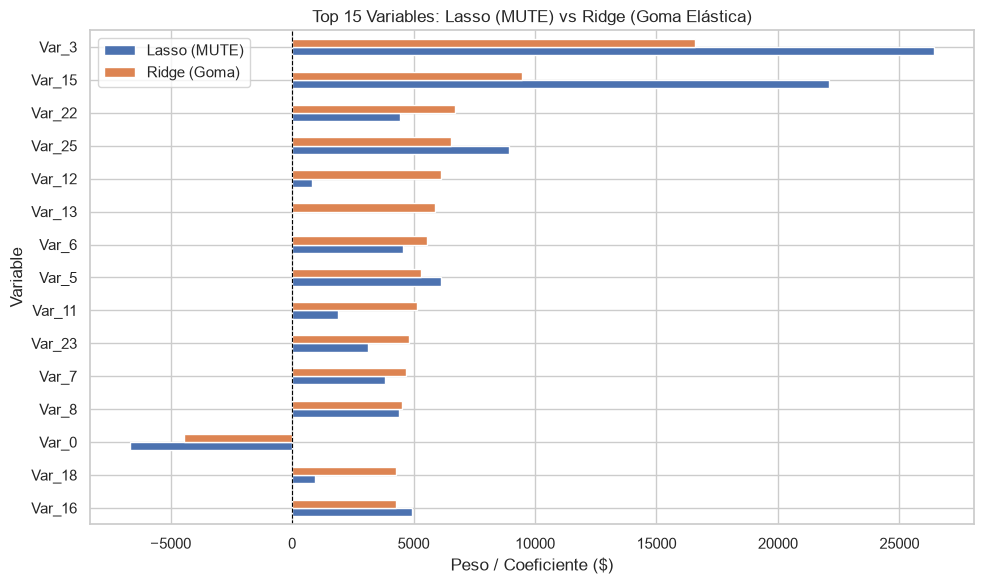

In [15]:
import numpy as np
import pandas as pd
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

# Punto 1: Entrenamos RidgeCV y mostramos el alpha elegido
scaler = StandardScaler()  # Crea el escalador de variables
X_train_scaled = scaler.fit_transform(X_train)  # Vuelve a generar X_train_scaled por si la memoria se reseteo
alphas = np.logspace(-3, 3, 100)  # Rejilla de 100 alphas identica a la de Lasso
ridge_cv = RidgeCV(alphas=alphas).fit(X_train_scaled, y_train)  # Entrena RidgeCV sobre la rejilla de alphas
print(f"Alpha elegido por Ridge: {ridge_cv.alpha_}")  # Muestra en pantalla el alpha ganador

#aqui seleccionamos el aplha, este se elige segun las pruebas que se hagan

#Sale un ridge mas grande por que necesitmaos un numero mas gramde de alphas que lasso ya que este los coge a todos y necesita bajarlos a todos en cambio lasso es mas pequeño y necesita menos alphas para encontrar el mejor (lasso aplphas mas pequeño, ridge aplhpas mas gramnde) (lasso multa mas pequeña, ridge multa mas grande)

#-------------------------------------------------------------------------

# Punto 2: Evaluar el RMSE en test y comparar Ridge con Lasso en una sola tabla
X_test_scaled = scaler.transform(X_test)  # Escala los datos de test con el mismo escalador de entrenamiento
rmse_ridge = np.sqrt(mean_squared_error(y_test, ridge_cv.predict(X_test_scaled)))  # Calcula el error medio RMSE de Ridge en test
rmse_lasso = np.sqrt(mean_squared_error(y_test, lasso_cv.predict(X_test_scaled)))  # Calcula el error medio RMSE de Lasso en test
tabla_rmse = pd.DataFrame({'Modelo': ['Lasso', 'Ridge'], 'RMSE Test': [rmse_lasso, rmse_ridge]})  # Crea la tabla comparativa con los dos modelos
print(tabla_rmse)  # Muestra la tabla comparativa con los errores en pantalla

#despues de entrenar lols modelso seleccionamos el mejor rmse comparamos los dos y vemos

#-------------------------------------------------------------------------

# Punto 4: Comparar directamente lo que hicieron Lasso y Ridge con los 5 canales de ruido
coefs_ruido_lasso = lasso_cv.coef_[-5:]  # Extrae la posicion de los 5 mandos de ruido en la mesa Lasso
coefs_ruido_ridge = ridge_cv.coef_[-5:]  # Extrae la posicion de los 5 mandos de ruido en la mesa Ridge
tabla_ruido = pd.DataFrame({'Canal Ruido': [f'Ruido_{i+1}' for i in range(5)], 'Lasso (MUTE)': coefs_ruido_lasso, 'Ridge (Goma)': coefs_ruido_ridge})  # Crea la tabla comparativa del ruido
print(tabla_ruido)  # Muestra en pantalla como Lasso puso ceros exactos y Ridge dejo numeros pequeños

#aqui comparamos las 5 varaibles de lasso y las 5 variables de ridge y el valor de los coeficientes 


# Punto 5: Gráfico de barras comparativo para las 15 variables más importantes
nombres_vars = X_train.columns if hasattr(X_train, 'columns') else [f'Var_{i}' for i in range(X_train.shape[1])]  # Genera etiquetas para los canales de la mesa
top15_idx = np.argsort(np.abs(ridge_cv.coef_))[-15:]  # Identifica los 15 mandos con mayor volumen absoluto en la mesa
df_top15 = pd.DataFrame({'Variable': [nombres_vars[i] for i in top15_idx], 'Lasso (MUTE)': lasso_cv.coef_[top15_idx], 'Ridge (Goma)': ridge_cv.coef_[top15_idx]})  # Prepara los datos del top 15
df_top15.plot(x='Variable', y=['Lasso (MUTE)', 'Ridge (Goma)'], kind='barh', figsize=(10, 6))  # Genera el grafico de barras horizontales
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)  # Dibuja la linea vertical del cero como referencia
plt.title('Top 15 Variables: Lasso (MUTE) vs Ridge (Goma Elástica)')  # Asigna titulo explicativo al grafico
plt.xlabel('Peso / Coeficiente ($)')  # Define el eje horizontal como el impacto en dolares
plt.tight_layout()  # Ajusta los espacios para que no se corten los nombres de los canales
plt.show()  # Muestra la comparativa visual en pantalla

#lasso gana por que silencia el ruido 





#QUE ES UN COEFICIENTE??????????????????


### Mis reflexiones

*(Escribe aquí tu respuesta)*

- Has recomendado un modelo a cada equipo. Escribe, en dos frases y sin tecnicismos, lo que le dirías a cada uno. Ahora imagina que se sientan juntos y comparan lo que les has dicho: ¿te sostiene el argumento?
- El coeficiente de `GrLivArea` es aproximadamente el doble en Lasso que en Ridge. ¿Significa eso que un modelo cree que la superficie importa el doble que el otro? Si no, ¿qué significa?
- Los tres modelos se diferencian en menos del 1 % de RMSE. ¿Qué otra información pedirías antes de decidir, que no esté en este notebook?
- ¿Qué tendría que pasar para que cambiaras de recomendación? Da una condición concreta y comprobable, no "si los datos fueran distintos".

1- A negocio le daria la de lassp ya que quitamos las vairbales basura y dejka solo las claves, nos facilita explicar el precio al client sin irnos por las ramas
A ingenieria le daria la de riges por que reparte el peso entre todas las variables, evitando depende de algunas columnas 

Si que sostendria por alguna parte uno busca simplicidad y mas rapido y facil (quitar ruido) otro busca robustez es decir verlo todo sin quitar aquellas que puedan llegar a tener menos importancia 

2- No, no quiere decir eso, si no que lasso apaga unas variables y le da mas importamcia a otras por eso vemos mas importancia en cambio ridge reparte las fuerzas, no importa el doble si no que una reparte fuerzas y la otra aplsta y da mas valor a las que se mantienen en pie

3- Podriamos pedir el tiempo que tardan en eejcutarse estas, si una es mas rapida que otra y fuerza del server, y depsues tambien miraria si hace fatla justificar todo y eso, para ver si nos merece la pensa quedarnos con menos o mas datos, ridge o lasso 

4- Ahora mismo elegimos lasso, por que muchas de las columnas han sido elimindas, si llegara un momento en el que esas columnas si que fueran importantes no nos vendria bien que fueran borradas por lo tnato tendriamos que elegir ridge que no borra estas variables

---
## Ejercicio 3 — Cuando la regularización no sirve de nada

**Contexto.** Te cambian de proyecto. Ahora es una inmobiliaria que opera en California y el dataset es **California Housing**: 20.640 distritos, pero solo **8 variables** numéricas (longitud, latitud, antigüedad de la vivienda, habitaciones, dormitorios, población, hogares e ingreso medio). El objetivo es `median_house_value`.

Tu jefe de proyecto, que estuvo en la reunión anterior, te dice: *"aplica lo mismo que en Ames, que funcionó muy bien"*.

**Tu tarea.**
1. Carga California Housing desde la URL que tienes abajo, quédate con las columnas numéricas e imputa los nulos con la mediana.
2. Inyecta las mismas **5 columnas de ruido** que usaste en clase.
3. **Escala correctamente**: parte primero en train y test, y ajusta el `StandardScaler` **solo con los datos de entrenamiento**. Fíjate en que esto **no** es lo que hicimos en clase, y guárdate la observación para la última reflexión.
4. Entrena `LinearRegression`, `LassoCV` y `RidgeCV`, y compara sus RMSE en test.
5. Cuenta cuántas variables descarta Lasso aquí, incluidas las de ruido.
6. Calcula la relación filas/columnas en los dos datasets, Ames y California, y ponlas una al lado de la otra.

**Criterio de que lo has hecho bien:** los tres modelos van a quedar prácticamente empatados, mucho más que en Ames, y Lasso apenas va a descartar nada. Si te sale así, no te has equivocado: **el resultado del ejercicio es que la técnica no aporta**. Lo que se evalúa es que sepas explicar por qué, y que el número del punto 6 aparezca en tu explicación.

**Entrega:** el notebook con las celdas completadas y las reflexiones escritas.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV
from sklearn.metrics import mean_squared_error

# Punto 1: Cargar datos, filtrar columnas numéricas e imputar nulos con la mediana
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"  # O la URL que aparezca en tu celda
df = pd.read_csv(url)  # Carga el dataset completo desde la URL

df_numeric = df.select_dtypes(include=[np.number])  # Se queda únicamente con las columnas de tipo numérico
df_numeric = df_numeric.fillna(df_numeric.median())  # Rellena los valores nulos usando la mediana de cada columna

#en esta parte del code, lo que hacemos es importamso el dataset, y despues ponemos el panda pd.funcion(url) despues nos quedamos con las numericas y despues rellenamos los nulos con la mediana por columna 


#Punto 2 inyectamos el ruido 
# Punto 2: Inyectar 5 columnas de ruido aleatorio
np.random.seed(42)  # Fija la semilla para que los números aleatorios salgan siempre iguales, eso nos diuce que el ruido sea igual cada vez que ejecutemos la celda 
for i in range(5):  # Bucle que se repite 5 veces para crear 5 columnas
    df_numeric[f'ruido_{i+1}'] = np.random.normal(0, 1, size=len(df_numeric))  # Genera datos inventados (ruido gaussiano)
    #esrta simplemente mete ruido aleatorio 

#hacemos un bucle que se repite 5 veces para crear 5 columnas de ruido, el mismo ruido cada vez que ejecutemos la celda


# Punto 3: Separar X e y, dividir en train/test PRIMERO y escalar SOLO con train
X = df_numeric.drop(columns=['median_house_value'])  # Separa todas las columnas de entrada (características + ruido)
y = df_numeric['median_house_value']  # Separa únicamente la variable objetivo (precio de la vivienda)
#separamos estas variables, x = son las columnas, antiguedad, cordenadas, habitaciones, y las 5 de ruido
# y = es el precio medio de la casa, lo que queremos predecir

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # Hace la división primero (80% train, 20% test)

scaler = StandardScaler()  # Prepara la herramienta de escalado # ESTO ES EL ESCALADOR ES PARA PONER LOS VALROS AL MISMO NIVEL    HABITACION 1 O 2    INGRESOS DE LA ZONA 30.000 - 50.000 el standar coge las columnas y pasamos una escala unica centrada en el 0 
X_train_scaled = scaler.fit_transform(X_train)  # Calcula media/desviación SOLO con train y lo escala #  MIRAMOS LOS DATOS Y CALCULAMOS MEDIA Y DESVIACION 
X_test_scaled = scaler.transform(X_test)  # Aplica las reglas aprendidas de train para escalar test (sin hacer fit) USAMOS LA MEDIA Y DESVIACION QUE HEMOS CALCULADO ANTES para convertir los numero s una nueva escalada 

#-----------------------------------------------------------IMPORTANTE APUNTES--------------------------------------------#

# En Train: scaler.fit_transform(X_train)
#Le dices al escalador: "Mira los datos de entrenamiento, aprende su media y desviación (fit), y ahora transfórmalos (transform)".
#En Test: scaler.transform(X_test)
#Le dices al escalador: "Toma el grupo de examen (test) y transfórmalo (transform) usándome la regla que ya aprendiste con Train".
#No haces fit otra vez porque no quieres que el escalador mire o aprenda nada de los datos del examen (test). En un examen no puedes cambiar las reglas según las preguntas que te toquen; tienes que usar las reglas que estudiaste en el entrenamiento.


# Punto 4: Entrenar los modelos para obtener sus RMSE
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
rmse_lr = np.sqrt(mean_squared_error(y_test, lr.predict(X_test_scaled)))

lasso_cv = LassoCV(cv=5, random_state=42)
lasso_cv.fit(X_train_scaled, y_train)
rmse_lasso = np.sqrt(mean_squared_error(y_test, lasso_cv.predict(X_test_scaled)))

ridge_cv = RidgeCV(cv=5)
ridge_cv.fit(X_train_scaled, y_train)
rmse_ridge = np.sqrt(mean_squared_error(y_test, ridge_cv.predict(X_test_scaled)))

# Crear una tabla (DataFrame de Pandas) para comparar los resultados de forma ordenada
resultados_p4 = pd.DataFrame({
    # Columna 1: 'Modelo' -> Lista con los nombres textuales de los 3 algoritmos probados
    'Modelo': ['LinearRegression', 'LassoCV', 'RidgeCV'],
    
    # Columna 2: 'RMSE Test' -> Lista con los valores numéricos del error medio calculados en el examen (test)
    'RMSE Test': [rmse_lr, rmse_lasso, rmse_ridge]
})

# Imprime la tabla por pantalla para poder comparar visualmente el rendimiento de los 3 modelos
print(resultados_p4)


# Punto 5: Cuenta cuántas variables descarta Lasso
coeficientes_lasso = lasso_cv.coef_  # Extrae los pesos que le dio Lasso a cada una de las 13 variables
variables_descartadas = np.sum(coeficientes_lasso == 0)  # Cuenta cuántos coeficientes son exactos a 0 (eliminadas)
variables_conservadas = np.sum(coeficientes_lasso != 0)  # Cuenta cuántos coeficientes son distintos de 0 (mantenidas)

print(f"Total de variables iniciales: {len(X.columns)}")
print(f"Variables descartadas por Lasso: {variables_descartadas}")
print(f"Variables conservadas por Lasso: {variables_conservadas}")

# Muestra el detalle variable por variable
desglose_coeficientes = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': coeficientes_lasso
})
print(desglose_coeficientes)



# Punto 6: Calcular la relación filas/columnas en Ames y California y ponerlas lado a lado

# 1. Datos del dataset de California (usando las variables que ya tenemos cargadas)
filas_cal = len(df_numeric)  # 20.640 filas
cols_cal = len(X.columns)    # 13 columnas explicativas (8 reales + 5 de ruido)
relacion_cal = filas_cal / cols_cal

# 2. Datos del dataset de Ames (de los ejercicios anteriores)
# Nota: Si conservas 'X_ames' en tu notebook puedes hacer len(X_ames), si no, usamos sus valores reales (2.930 filas y 41 variables)
filas_ames = 2930
cols_ames = 41
relacion_ames = filas_ames / cols_ames

# 3. Crear DataFrame para mostrar ambas relaciones una al lado de la otra
tabla_relacion = pd.DataFrame({
    'Dataset': ['California Housing', 'Ames Housing'],
    'Filas (N)': [filas_cal, filas_ames],
    'Columnas X (P)': [cols_cal, cols_ames],
    'Relación (Filas / Cols)': [relacion_cal, relacion_ames]
})

print(tabla_relacion)

### Mis reflexiones finales

*(Escribe aquí tu respuesta)*

- Tu jefe te dijo "aplica lo mismo que en Ames, que funcionó muy bien". Escríbele la respuesta: tres o cuatro frases, sin jerga, explicando qué has hecho y por qué aquí no aporta. No vale decir solo "el dataset es distinto".

- Da una regla práctica que puedas aplicar **antes** de entrenar nada para sospechar si la regularización te va a servir en un problema nuevo. Tiene que ser algo que puedas calcular mirando el dataset, y tiene que poder fallar: si tu regla acierta siempre, es que no dice nada.

- Compara el orden de los pasos de preparación en este ejercicio y en los dos anteriores. Hay una diferencia deliberada. Encuéntrala, explica por qué una de las dos formas es incorrecta y razona si en este caso concreto habría cambiado mucho el resultado.

- Has visto tres modelos empatados en Ames y tres modelos empatados en California, por motivos distintos en cada caso. ¿En qué se diferencian los dos empates?

- Si tuvieras que llevar a producción el modelo de Ames, ¿qué añadirías a este notebook antes de que alguien lo use sin ti delante?

------------------------------------------------------------------------------------------------------------------------------------------

1- Se ha aplicado el mismo metodo lo que pasa que aqui no apprta nada ya que antesn teniamos 28 viviendas por cada variable con tan pocos datos el modelo tenia en cuenta vairable sin valor, aqui hay 1270 distritos por vriable aqui hay datos de sobra para que el modelo no se deje engañar. Antes en ames solucionabaamos un problema que aqui no existem en ames muy poca info y muuchas columnas de mierdaç


2- calculamos la relacion dividiendo el numero de filas entre las columnas si el resultados es menor a 100 hay riesgo de necesitas lasso o ridge, si es de varios cientos de miles con regresion noral podriamos funcionar

Puede fallar si tienes muchísimas filas pero varias columnas son casi idénticas entre sí (alta multicolinealidad). Ahí la regularización sí te ayudará a estabilizar el modelo, aunque la regla te diga que no la necesitas.

3- En este ejercicio hizimos el train test antes de ecalar, antes se escalaba todo el dataset y despues se entrenaba, 

Antes estaba mal por que si calculamos la media y desviacion tipica con todos los datos, los datos de entrenamiento se pueden empaapar de algo de info de la informacion de test del final, antes de evaluar, es como que los datos de test cotillean la info de examen

No habria cmabiado el reszultado, al tener mas de 20.000 filas la media y la desviacion de el conjunto entero y del 80% son practicamente identicas, por lo que el rsme no hubiera cambiado mucho 

4- En este tenemos un empate por falta de sobreajuste, hay tantos datos que la regresion linea aprendie bien sin memorizar ruido, lasso y ridge no tienen que penalizar casi nada, por lo que lso 3 modelos hacen ams o menos lo mismo

En AMES es un empate al haber tantas variables para pocas filas, la regresion sufre de sobreajuste, lasso y ridge aqui si que frenan variables


5- Documentación del alcance (Límites de uso): Explicaría que este modelo funciona muy bien cuando disponemos de pocas filas y muchas variables con posible ruido, ya que Lasso/Ridge saben filtrar y quitar importancia a columnas no relevantes. Aclararía que no debe usarse para datasets de pocas columnas (8-15) donde todas son importantes, ni en regiones fuera de Ames.

------------------------------------------------------------------------------------------------------------------------------------------

1. Respuesta al jefe

“He aplicado el mismo método, pero en California no aporta nada. En Ames teníamos unas 28 viviendas por cada variable, y con tan pocos datos el modelo se dejaba engañar por variables sin valor, por lo que había que frenarlo. Aquí hay unos 1.270 distritos por cada variable, así que hay datos de sobra para que el modelo no se deje engañar y los tres modelos dan casi lo mismo. Lo que funcionó en Ames fue arreglar un problema que aquí no existe.”

2. Regla práctica antes de entrenar

Calcular la relación filas/columnas del conjunto de entrenamiento. Si es baja (por debajo de unas 30 a 1, como Ames), sospecho que la regularización ayudará, y si es muy alta (cientos o miles a 1, como California), sospecho que no. Puede fallar: con una relación alta pero muchas variables casi duplicadas (por ejemplo, tras convertir texto en muchas columnas), la regularización puede seguir ayudando. Además, una relación baja no garantiza mejora si casi todas las variables son útiles. Por eso la regla da una sospecha, no una certeza, y se confirma comparando los RMSE.

3. Diferencia en el orden de los pasos

En Ames se escaló antes de dividir en train y test, y aquí se divide primero y el scaler se ajusta solo con train. La forma de Ames es incorrecta porque la media y la desviación se calculan usando también las casas de test, así que el test deja de ser “datos que el modelo no ha visto” y se filtra información (data leakage). En este caso concreto habría cambiado muy poco: con 16.512 filas de entrenamiento, la media y la desviación de train y de todo el dataset son casi idénticas. En Ames, con menos datos, el efecto tampoco debería ser grande. Eso no la hace correcta: en datasets pequeños o con valores extremos sí puede notarse, y se comprueba repitiendo el ejercicio con ambos órdenes.

4. Diferencia entre los dos empates

En Ames el empate es de precisión, pero no de estructura: los tres modelos aciertan casi igual, pero Lasso lo logra con 18 variables menos (ganó simplicidad, no precisión) y Ridge se quedó con el ruido. En California hay empate de todo: con 8 variables útiles y miles de filas no hay nada que simplificar, y Lasso apenas descarta nada, así que los tres modelos son prácticamente el mismo. Además, el error que queda en California es sobre todo del modelo lineal, que es demasiado simple para este problema. La regularización solo corrige el sobreajuste, y no arregla eso.

5. Qué añadiría para llevar a producción el modelo de Ames

Un Pipeline con el scaler y el modelo juntos, para que el escalado no se filtre y se aplique igual a datos nuevos.
Una validación con datos que el modelo no haya visto nunca (por ejemplo, ventas posteriores en el tiempo), no solo un split aleatorio.
Revisar el error por tramos de precio (casas baratas, medias y muy caras), porque un RMSE global puede esconder fallos grandes en un tramo.
Incluir las variables de texto que ahora se descartan, y gestionar casas atípicas y variables nuevas o fuera de rango.
Eliminar las columnas de ruido (solo eran un control) y guardar el modelo con su versión y fecha.
Monitorizar el error con datos reales una vez en uso, para detectar cuándo el mercado cambia y hay que reentrenar.

#------------------------------------------------------------------------------------------------------------------------------------------------------------------
#APUNTES
#--------------------------------------------------------------------------------------------------------------------------------------------------#


1. Carga de Datos 
   ==> Se cargan las características reales de la casa y se le añaden las 5 columnas de ruido artificial.

2. División del Dataset (Train / Test)
   ==> Separamos en datos de Entrenamiento (para que el modelo aprenda) y Prueba/Test (para el examen final).

3. Estandarización de Valores (StandardScaler)
   ==> Se ajustan todas las columnas a la misma escala (media 0 y desviación 1) para que los metros cuadrados y el número de baños se midan por igual.

4. Búsqueda de la Penalización Mágica (RidgeCV / LassoCV)
   ==> El modelo prueba una lista de 100 valores de alpha mediante validación cruzada para encontrar la fuerza de castigo que da menor error.

5. Asignación de Pesos / Coeficientes
   ==> Lasso pone a 0.0 las variables inútiles (borra el ruido); Ridge reduce el tamaño de todos los coeficientes pero los mantiene todos vivos.

6. Generación de Predicciones en Test (predict)
   ==> Se le pasa X_test_scaled al modelo para que multiplique las características de cada casa por sus coeficientes y devuelva el precio predicho en dólares.

7. Cálculo del Margen de Error (RMSE)
   ==> Se resta el precio predicho del precio real (y_test), se eleva al cuadrado, se saca la media y se aplica la raíz cuadrada para medir la desviación media en dólares.

# Explicación Visual: Coeficientes, Regresión Ridge y Lasso

## 1. ¿Qué es un coeficiente en la vida real?
Imagina una mesa de mezclas de sonido llena de **mandos giratorios**. Cada mando representa una columna de tu tabla de datos:
* Un mando para los **Metros cuadrados**.
* Un mando para los **Baños**.
* Un mando para el **Año de construcción**.
* Un mando para la **Variable de ruido** (una columna inventada).

El **coeficiente** es simplemente la posición en la que dejas girado cada mando:
* Si giras el mando de *Metros cuadrados* hasta **1.000**, significa que cada m² suma 1.000 $ al precio final.
* Si el mando de *Año de construcción* lo giras a **-500**, significa que cada año de antigüedad resta 500 $.
* Si un mando está en **0**, significa que esa columna no afecta en nada al precio final.

---

## 2. ¿Cómo calcula la máquina esos coeficientes?
La máquina al principio no tiene ni idea de cuánto vale un metro cuadrado ni un baño. Lo descubre por **ensayo y error**:
1. Coge las casas de entrenamiento con sus precios reales.
2. Coloca todos los mandos en posiciones al azar y calcula un precio estimado para cada casa.
3. Mira la diferencia entre lo que ha estimado y el precio real en la vida real.
4. Va moviendo levemente los mandos hacia arriba y hacia abajo buscando la combinación exacta de mandos con la que cometa el menor fallo posible.

---

## 3. El problema del ruido (por qué necesitamos a Ridge)
Si metes una columna inventada de basura (por ejemplo, *el color del coche del vecino*), por pura coincidencia en algunas casas caras el vecino tendrá un coche rojo.

Una regresión normal se engaña sola: girará el mando del *coche del vecino* hacia arriba creyendo que eso suma valor.

Ahí es donde entra **Ridge**. Ridge le pone una **goma elástica** a cada mando que tira de ellos constantemente hacia abajo (hacia el cero):
* **Para los Metros cuadrados:** Como esta variable ayuda muchísimo a acertar los precios, la máquina empuja el mando con mucha fuerza hacia arriba, venciendo la resistencia de la goma elástica. El mando se queda arriba (ejemplo: 1.000 $).
* **Para el Ruido:** Como esta columna no ayuda a predecir nada real, no hay ninguna fuerza empujando el mando hacia arriba. La goma elástica gana la partida y arrastra el mando casi hasta el suelo.

---

## 4. ¿Por qué Ridge deja números pequeños pero nunca el 0.0 exacto?
Porque la goma elástica de Ridge empuja con menos fuerza cuanto más cerca está del suelo. Cuando el mando ya está casi tocando el cero (en **0.001**), la goma apenas hace fuerza, así que la máquina lo deja ahí flotando pegado al suelo, pero sin tocar el 0.0 exacto.

**Lasso**, en cambio, no usa una goma elástica: usa una **guillotina**. Si ve que un mando no aporta nada, le pega un corte limpio y lo deja clavado en el **0.0 absoluto** (elimina la variable).